<a href="https://colab.research.google.com/github/Forgottenpet/Modulo1-Notebooks2/blob/main/Notebook3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Librerías para manejo de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller, kpss, acf
from google.colab import files

## Carga y preparación de los datos


In [ ]:
# Subir el archivo CSV o CSV.GZ
archivo_subido = files.upload()

# Obtener automáticamente el nombre del archivo
nombre_archivo = next(iter(archivo_subido))

# Leer el archivo
datos = pd.read_csv(
    nombre_archivo,
    skiprows=9,
    compression='infer'
)

print("Dimensiones del dataset:", datos.shape)
print("\nColumnas:")
print(datos.columns.tolist())

datos.head()

Saving contaminantes_2026.csv to contaminantes_2026.csv
Dimensiones del dataset: (1556928, 5)

Columnas:
['date', 'id_station', 'id_parameter', 'valor', 'unit']


,date,id_station,id_parameter,valor,unit
0,2026-01-01 00:00:00,ACO,CO,NaN,15
1,2026-01-01 00:00:00,ACO,NO,NaN,1
2,2026-01-01 00:00:00,ACO,NO2,NaN,1
3,2026-01-01 00:00:00,ACO,NOX,NaN,1
4,2026-01-01 00:00:00,ACO,O3,NaN,1


In [ ]:
# Convertir la columna de fecha
datos['date_dt'] = pd.to_datetime(datos['date'], errors='coerce')

if 'hour' in datos.columns:
    datos['hora'] = pd.to_numeric(datos['hour'], errors='coerce')
    datos['timestamp'] = datos['date_dt'].dt.normalize() + pd.to_timedelta(datos['hora'], unit='h')
else:
    datos['timestamp'] = datos['date_dt']
    datos['hora'] = datos['timestamp'].dt.hour

print("Horas encontradas:")
print(sorted(datos['hora'].dropna().unique()))

Horas encontradas:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20), np.int32(21), np.int32(22), np.int32(23)]


In [ ]:
# Seleccionar únicamente O3 de la estación UIZ
o3_uiz = datos[(datos['id_station'] == 'UIZ') & (datos['id_parameter'] == 'O3')].copy()

o3_uiz['valor'] = pd.to_numeric(o3_uiz['valor'], errors='coerce')

# Ordenar cronológicamente
o3_uiz = o3_uiz.sort_values('timestamp')

print("Número de registros encontrados:", len(o3_uiz))

o3_uiz[['timestamp', 'id_station', 'id_parameter', 'valor']].head()

Número de registros encontrados: 5088


,timestamp,id_station,id_parameter,valor
283,2026-01-01 00:00:00,UIZ,O3,14.0
589,2026-01-01 01:00:00,UIZ,O3,5.0
895,2026-01-01 02:00:00,UIZ,O3,2.0
1201,2026-01-01 03:00:00,UIZ,O3,3.0
1507,2026-01-01 04:00:00,UIZ,O3,3.0


## a) Conteo y tratamiento de huecos

In [ ]:
# Crear una serie temporal usando timestamp como índice
serie_original = o3_uiz.set_index('timestamp')['valor'].sort_index()

serie_original = serie_original.groupby(level=0).mean()
indice_completo = pd.date_range(start=serie_original.index.min(), end=serie_original.index.max(), freq='h')

# Reindexar para hacer visibles las horas faltantes
serie_horaria = serie_original.reindex(indice_completo)
serie_horaria.index.name = 'timestamp'

print("Total de horas esperadas:", len(serie_horaria))
print("Valores disponibles:", serie_horaria.notna().sum())
print("Huecos encontrados:", serie_horaria.isna().sum())

porcentaje_huecos = serie_horaria.isna().mean() * 100
print(f"Porcentaje de huecos: {porcentaje_huecos:.2f}%")

Total de horas esperadas: 5088
Valores disponibles: 4860
Huecos encontrados: 228
Porcentaje de huecos: 4.48%


In [ ]:
# Identificar secuencias consecutivas de valores faltantes
es_hueco = serie_horaria.isna()
grupos = es_hueco.ne(es_hueco.shift()).cumsum()
longitud_huecos = es_hueco[es_hueco].groupby(grupos[es_hueco]).size()

if len(longitud_huecos) > 0:
    print("Número de bloques de huecos:", len(longitud_huecos))
    print("Hueco más largo:", longitud_huecos.max(), "horas")
    print("\nLongitud de los huecos:")
    print(longitud_huecos.value_counts().sort_index())
else:
    print("No se encontraron huecos.")

Número de bloques de huecos: 68
Hueco más largo: 49 horas

Longitud de los huecos:
valor
1     19
2      3
3     33
4      9
5      1
6      1
8      1
49     1
Name: count, dtype: int64


In [ ]:
serie = serie_horaria.interpolate(method='time', limit_area='inside')

# Eliminar posibles faltantes que hayan quedado en los extremos
serie = serie.dropna()

print("Huecos después del tratamiento:", serie.isna().sum())
print("Observaciones disponibles:", len(serie))

Huecos después del tratamiento: 0
Observaciones disponibles: 5088


## b) Serie temporal y ACF hasta 72 horas

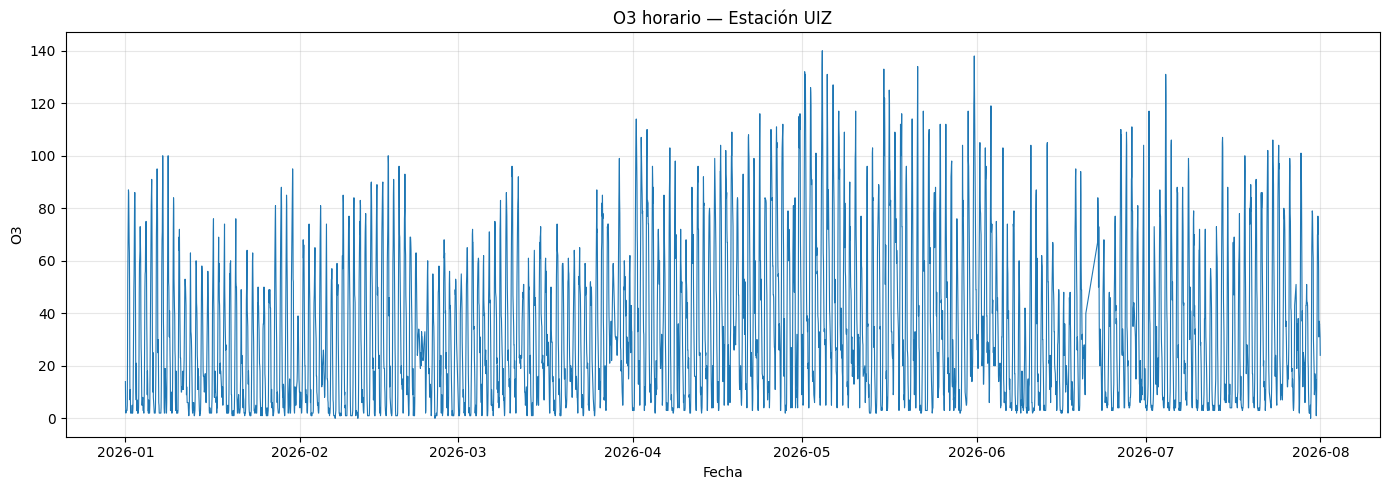

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(serie.index, serie.values, linewidth=0.8)
plt.title('O3 horario — Estación UIZ')
plt.xlabel('Fecha')
plt.ylabel('O3')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

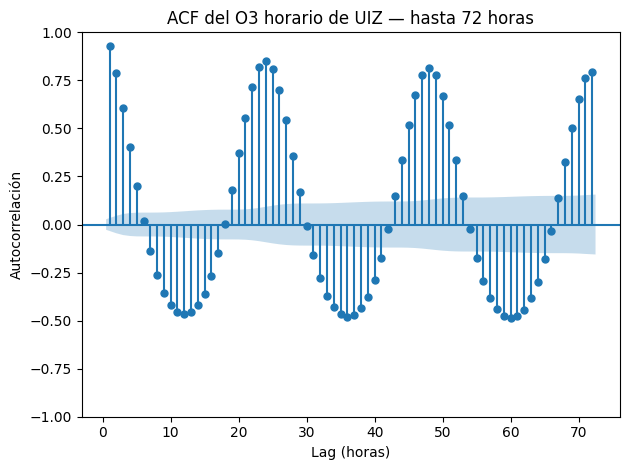

In [ ]:
# ACF hasta 72 horas
plot_acf(serie, lags=72, zero=False)
plt.title('ACF del O3 horario de UIZ — hasta 72 horas')
plt.xlabel('Lag (horas)')
plt.ylabel('Autocorrelación')
plt.tight_layout()
plt.show()

## c) Pruebas ADF y KPSS

In [ ]:
def pruebas_estacionariedad(serie_analizar, nombre):
    # Eliminar posibles valores faltantes
    x = serie_analizar.dropna()

    print("=" * 60)
    print(nombre)
    print("=" * 60)

    # Prueba ADF
    resultado_adf = adfuller(x, autolag='AIC')
    estadistico_adf = resultado_adf[0]
    p_adf = resultado_adf[1]

    print("\nADF")
    print(f"Estadístico: {estadistico_adf:.6f}")
    print(f"p-value: {p_adf:.6f}")

    if p_adf < 0.05:
        print("Conclusión ADF: se rechaza H0.")
        print("La prueba ADF proporciona evidencia de estacionariedad.")
    else:
        print("Conclusión ADF: no se rechaza H0.")
        print("La prueba ADF no proporciona evidencia suficiente de estacionariedad.")

    # Prueba KPSS
    resultado_kpss = kpss(x, regression='c', nlags='auto')
    estadistico_kpss = resultado_kpss[0]
    p_kpss = resultado_kpss[1]

    print("\nKPSS")
    print(f"Estadístico: {estadistico_kpss:.6f}")
    print(f"p-value: {p_kpss:.6f}")

    if p_kpss < 0.05:
        print("Conclusión KPSS: se rechaza H0.")
        print("La prueba KPSS proporciona evidencia de no estacionariedad.")
    else:
        print("Conclusión KPSS: no se rechaza H0.")
        print("La prueba KPSS es compatible con estacionariedad.")

In [ ]:
pruebas_estacionariedad(serie, "Serie original de O3")

Serie original de O3

ADF
Estadístico: -5.928836
p-value: 0.000000
Conclusión ADF: se rechaza H0.
La prueba ADF proporciona evidencia de estacionariedad.

KPSS
Estadístico: 2.590817
p-value: 0.010000
Conclusión KPSS: se rechaza H0.
La prueba KPSS proporciona evidencia de no estacionariedad.


/tmp/ipykernel_691/4285332895.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf = adfuller(x, autolag='AIC')
/tmp/ipykernel_691/4285332895.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  resultado_kpss = kpss(x, regression='c', nlags='auto')
/tmp/ipykernel_691/4285332895.py:26: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returnin

## d) Restar la media de cada hora del día y repetir c)

In [ ]:
datos_hora = pd.DataFrame({'O3': serie})
datos_hora['hora'] = datos_hora.index.hour

media_por_hora = datos_hora.groupby('hora')['O3'].transform('mean')

datos_hora['O3_sin_media_hora'] = datos_hora['O3'] - media_por_hora
serie_hora = datos_hora['O3_sin_media_hora']

serie_hora.head()

,O3_sin_media_hora
timestamp,
2026-01-01 00:00:00,0.666080
2026-01-01 01:00:00,-7.891107
2026-01-01 02:00:00,-10.155841
2026-01-01 03:00:00,-7.994474
2026-01-01 04:00:00,-6.723962


In [ ]:
pruebas_estacionariedad(serie_hora, "O3 después de restar la media de cada hora del día")

O3 después de restar la media de cada hora del día

ADF
Estadístico: -5.927254
p-value: 0.000000
Conclusión ADF: se rechaza H0.
La prueba ADF proporciona evidencia de estacionariedad.

KPSS
Estadístico: 2.739910
p-value: 0.010000
Conclusión KPSS: se rechaza H0.
La prueba KPSS proporciona evidencia de no estacionariedad.


/tmp/ipykernel_691/4285332895.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf = adfuller(x, autolag='AIC')
/tmp/ipykernel_691/4285332895.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  resultado_kpss = kpss(x, regression='c', nlags='auto')
/tmp/ipykernel_691/4285332895.py:26: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returnin

## e) Restar la media de cada mes × hora y repetir c)

In [ ]:
datos_mes_hora = pd.DataFrame({'O3': serie})
datos_mes_hora['mes'] = datos_mes_hora.index.month
datos_mes_hora['hora'] = datos_mes_hora.index.hour

media_mes_hora = datos_mes_hora.groupby(['mes', 'hora'])['O3'].transform('mean')

datos_mes_hora['O3_sin_media_mes_hora'] = datos_mes_hora['O3'] - media_mes_hora
serie_mes_hora = datos_mes_hora['O3_sin_media_mes_hora']

serie_mes_hora.head()

,O3_sin_media_mes_hora
timestamp,
2026-01-01 00:00:00,7.491935
2026-01-01 01:00:00,-1.274194
2026-01-01 02:00:00,-3.911290
2026-01-01 03:00:00,-2.419355
2026-01-01 04:00:00,-1.483871


In [ ]:
pruebas_estacionariedad(serie_mes_hora, "O3 después de restar la media de cada mes × hora")

O3 después de restar la media de cada mes × hora

ADF
Estadístico: -7.689729
p-value: 0.000000
Conclusión ADF: se rechaza H0.
La prueba ADF proporciona evidencia de estacionariedad.

KPSS
Estadístico: 0.048729
p-value: 0.100000
Conclusión KPSS: no se rechaza H0.
La prueba KPSS es compatible con estacionariedad.


/tmp/ipykernel_691/4285332895.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf = adfuller(x, autolag='AIC')
/tmp/ipykernel_691/4285332895.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  resultado_kpss = kpss(x, regression='c', nlags='auto')
/tmp/ipykernel_691/4285332895.py:26: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returnin

## f) Diferencia de 24 horas, repetir c) y comparar con e)

In [ ]:
# Diferencia entre cada observación y el valor observado 24 horas antes
serie_diff24 = serie.diff(24).dropna()

print("Observaciones después de diferenciar:", len(serie_diff24))
serie_diff24.head()

Observaciones después de diferenciar: 5064


,valor
timestamp,
2026-01-02 00:00:00,-12.0
2026-01-02 01:00:00,-3.0
2026-01-02 02:00:00,0.0
2026-01-02 03:00:00,-1.0
2026-01-02 04:00:00,0.0


In [ ]:
pruebas_estacionariedad(serie_diff24, "O3 con diferencia de 24 horas")

O3 con diferencia de 24 horas

ADF
Estadístico: -15.597720
p-value: 0.000000
Conclusión ADF: se rechaza H0.
La prueba ADF proporciona evidencia de estacionariedad.

KPSS
Estadístico: 0.008987
p-value: 0.100000
Conclusión KPSS: no se rechaza H0.
La prueba KPSS es compatible con estacionariedad.


/tmp/ipykernel_691/4285332895.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf = adfuller(x, autolag='AIC')
/tmp/ipykernel_691/4285332895.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  resultado_kpss = kpss(x, regression='c', nlags='auto')
/tmp/ipykernel_691/4285332895.py:26: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returnin

### Comparación de ACF

In [ ]:
# Calcular ACF de ambas series hasta 72 horas
acf_mes_hora = acf(serie_mes_hora.dropna(), nlags=72, fft=True)
acf_diff24 = acf(serie_diff24.dropna(), nlags=72, fft=True)
lags = np.arange(73)

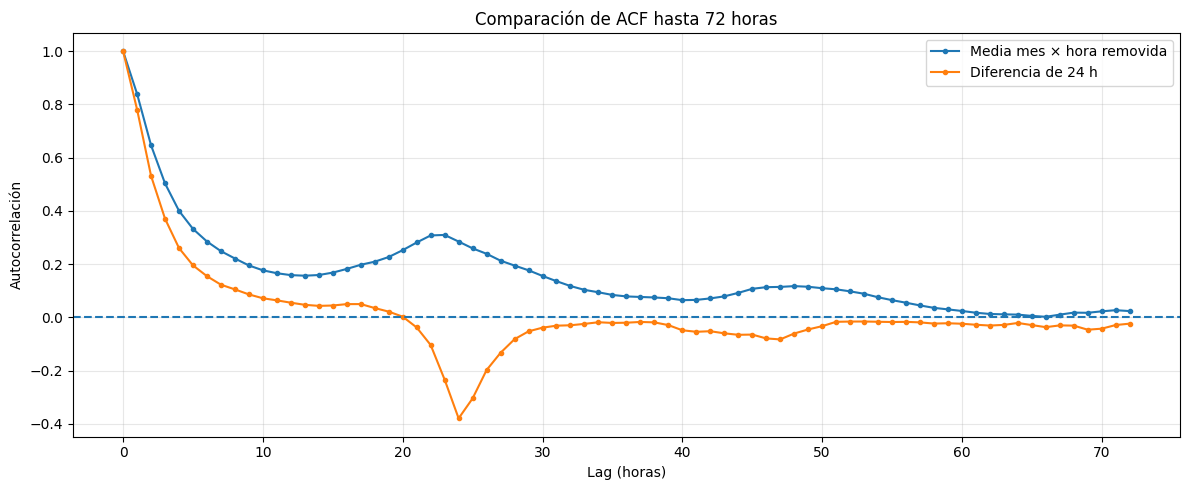

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(lags, acf_mes_hora, marker='o', markersize=3, label='Media mes × hora removida')
plt.plot(lags, acf_diff24, marker='o', markersize=3, label='Diferencia de 24 h')
plt.axhline(0, linestyle='--')

plt.xlabel('Lag (horas)')
plt.ylabel('Autocorrelación')
plt.title('Comparación de ACF hasta 72 horas')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Comparación de varianzas

In [ ]:
var_mes_hora = serie_mes_hora.var()
var_diff24 = serie_diff24.var()

comparacion_varianza = pd.DataFrame({
    'Serie': ['Media mes × hora removida', 'Diferencia de 24 h'],
    'Varianza': [var_mes_hora, var_diff24]
})

comparacion_varianza

,Serie,Varianza
0,Media mes × hora removida,165.231871
1,Diferencia de 24 h,241.978763


In [ ]:
print(f"Varianza después de quitar media mes × hora: {var_mes_hora:.4f}")
print(f"Varianza después de diferencia de 24 h: {var_diff24:.4f}")

if var_diff24 < var_mes_hora:
    print("\nLa serie diferenciada a 24 horas tiene menor varianza.")
elif var_diff24 > var_mes_hora:
    print("\nLa serie después de quitar la media mes × hora tiene menor varianza.")
else:
    print("\nAmbas series tienen la misma varianza.")

Varianza después de quitar media mes × hora: 165.2319
Varianza después de diferencia de 24 h: 241.9788

La serie después de quitar la media mes × hora tiene menor varianza.
